In [1]:
import pandas as pd
df = pd.read_csv("shopping_data.csv")


In [2]:

df.shape



(200, 5)

In [3]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
df.rename(columns={"Genre":"Gender"},inplace=True)

In [5]:
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


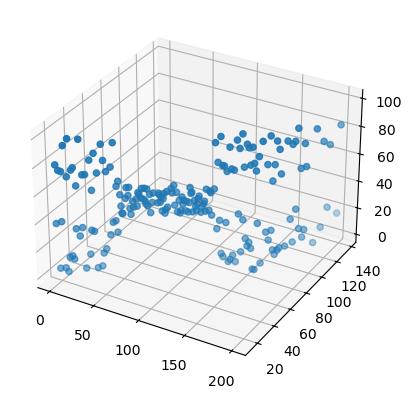

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df.iloc[:,0],df.iloc[:,3],df.iloc[:,4])
plt.show()

In [7]:
df_new=pd.get_dummies(df,dtype=int)

In [8]:
df_new

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Gender_Female,Gender_Male
0,1,19,15,39,0,1
1,2,21,15,81,0,1
2,3,20,16,6,1,0
3,4,23,16,77,1,0
4,5,31,17,40,1,0
...,...,...,...,...,...,...
195,196,35,120,79,1,0
196,197,45,126,28,1,0
197,198,32,126,74,0,1
198,199,32,137,18,0,1


In [9]:
df_new.drop('CustomerID',axis=1,inplace=True)

In [10]:
df_new

,Age,Annual Income (k$),Spending Score (1-100),Gender_Female,Gender_Male
0,19,15,39,0,1
1,21,15,81,0,1
2,20,16,6,1,0
3,23,16,77,1,0
4,31,17,40,1,0
...,...,...,...,...,...
195,35,120,79,1,0
196,45,126,28,1,0
197,32,126,74,0,1
198,32,137,18,0,1


In [11]:
from sklearn.cluster import KMeans

C:\Users\ExcelR Trainers\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ExcelR Trainers\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ExcelR Trainers\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ExcelR Trainers\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans 

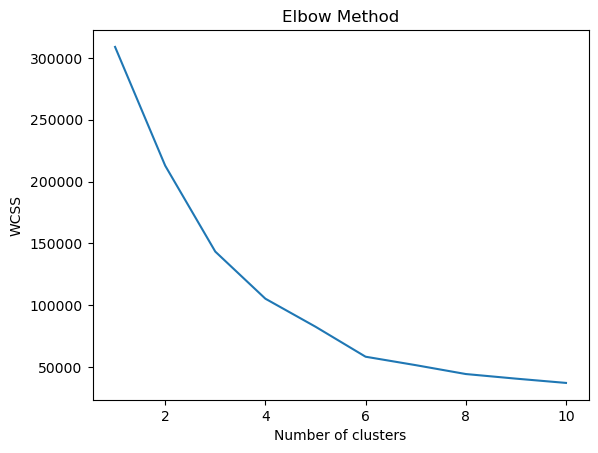

In [12]:
#elbow method : Elbow method to calculate number of clusters
wcss = []     # within cluster sum of squared(wcss = sum(distance between datapoint to cluster))
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i,random_state=0)
    kmeans.fit(df_new)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss)
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

In [13]:
km=KMeans(n_clusters=6,random_state=42)
km.fit(df_new)

C:\Users\ExcelR Trainers\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,n_clusters,6
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [14]:
from sklearn.metrics import silhouette_score
silhouette_score(df_new,km.labels_)

0.4150848039941013

In [15]:
df_kmean=df_new.copy()

In [16]:
df_kmean['Cluster_labels']=km.labels_

In [17]:
df_kmean

,Age,Annual Income (k$),Spending Score (1-100),Gender_Female,Gender_Male,Cluster_labels
0,19,15,39,0,1,5
1,21,15,81,0,1,2
2,20,16,6,1,0,5
3,23,16,77,1,0,2
4,31,17,40,1,0,5
...,...,...,...,...,...,...
195,35,120,79,1,0,1
196,45,126,28,1,0,3
197,32,126,74,0,1,1
198,32,137,18,0,1,3


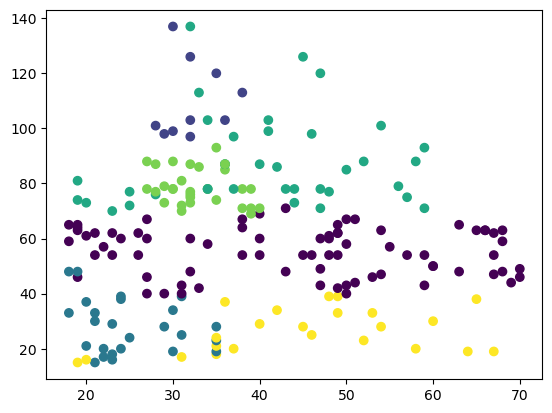

In [18]:
plt.scatter(df_kmean["Age"],df_kmean["Annual Income (k$)"],c=df_kmean['Cluster_labels'])

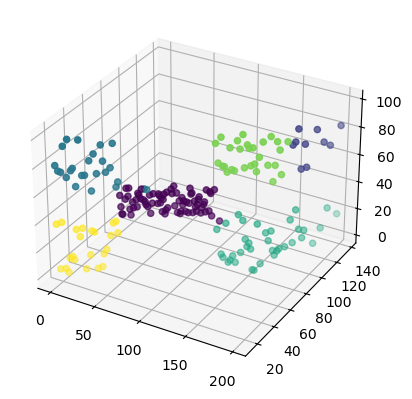

In [19]:
%matplotlib inline
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df_kmean.index,df_kmean["Annual Income (k$)"],df_kmean["Spending Score (1-100)"],c=df_kmean['Cluster_labels'])
plt.show()

In [20]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
pca_data=pca.fit_transform(df_new.iloc[:,:-1])

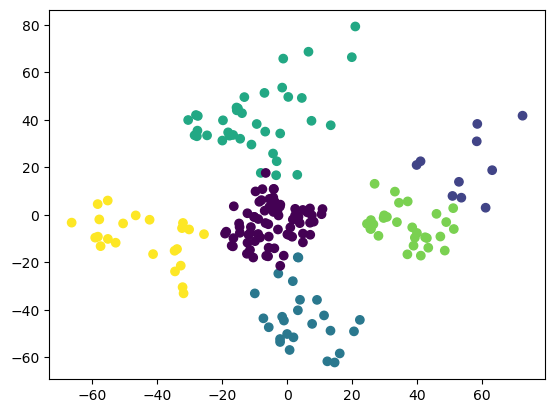

In [21]:
plt.scatter(x=pca_data[:,0],y=pca_data[:,1],c=df_kmean['Cluster_labels'])
plt.show()

## DBSCAN: 
Denstity based spatial Clustering of applications with noise. It is unsupervised machine learning algorithm.

It will form the groups based on the data points that are closely packed(high in density) and labels isolated points as noise.

Unlike Kmeans in DBSCAN not require to specify no of cluster.

# Imp Parameters: 

1. Epsilon value : It is radius around data points.
2. Minpts : Numbers of neighbors

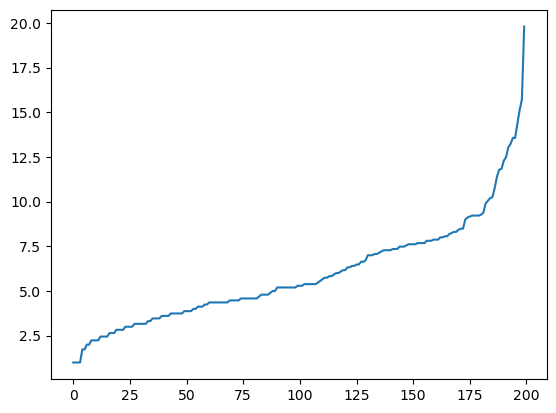

In [22]:
import numpy as np
from sklearn.neighbors import NearestNeighbors
neigh= NearestNeighbors()
nbrs=neigh.fit(df_new)
distances,indices=nbrs.kneighbors(df_new)
distances=np.sort(distances,axis=0)
distances=distances[:,1]
plt.plot(distances)
plt.show()

In [23]:
from sklearn.cluster import DBSCAN
db=DBSCAN(eps=13,min_samples=6)  # eps = 16
db.fit(df_new)

,eps,13
,min_samples,6
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


In [24]:
db.labels_

array([-1,  0, -1,  0, -1,  0, -1, -1, -1,  0, -1, -1,  1,  0, -1,  0,  0,
        0,  0, -1,  0,  0,  1,  0,  1,  0,  0,  0,  0,  0,  1,  0,  1,  0,
        1,  0, -1,  0, -1,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  2, -1,  2,  0,  2,  3,  2,  3,  2,  0,  2, -1,  2,
        3,  2, -1,  2,  3,  2, -1,  2, -1,  2,  0,  2,  3,  2,  3,  2,  3,
        2,  3,  2,  3,  2,  3,  2,  3,  2, -1,  2,  3,  2,  3,  2,  3,  2,
        3,  2,  3,  2,  3,  2,  3,  2,  3,  2, -1,  2,  3,  2, -1,  2, -1,
       -1, -1,  2, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1])

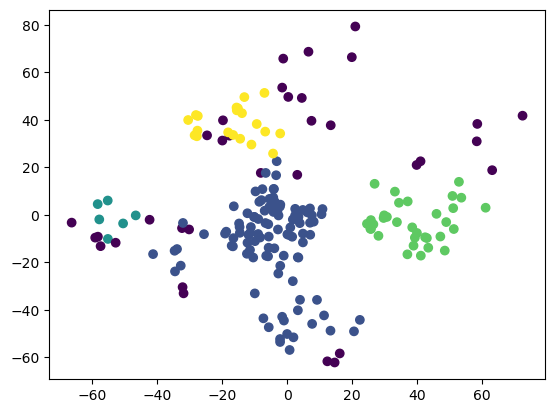

In [25]:
plt.scatter(x=pca_data[:,0],y=pca_data[:,1],c=db.labels_)
plt.show()

In [26]:

db.labels_

array([-1,  0, -1,  0, -1,  0, -1, -1, -1,  0, -1, -1,  1,  0, -1,  0,  0,
        0,  0, -1,  0,  0,  1,  0,  1,  0,  0,  0,  0,  0,  1,  0,  1,  0,
        1,  0, -1,  0, -1,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  2, -1,  2,  0,  2,  3,  2,  3,  2,  0,  2, -1,  2,
        3,  2, -1,  2,  3,  2, -1,  2, -1,  2,  0,  2,  3,  2,  3,  2,  3,
        2,  3,  2,  3,  2,  3,  2,  3,  2, -1,  2,  3,  2,  3,  2,  3,  2,
        3,  2,  3,  2,  3,  2,  3,  2,  3,  2, -1,  2,  3,  2, -1,  2, -1,
       -1, -1,  2, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1])

In [27]:
from sklearn.metrics import silhouette_score
silhouette_score(df_new,db.labels_)

0.23043585217888207

In [31]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

score = []
eps_values = range(12, 20)

for i in eps_values:
    db = DBSCAN(eps=i, min_samples=10)
    db.fit(df_new)

    labels = db.labels_

    if len(set(labels)) > 1 and -1 not in set(labels):
        s = silhouette_score(df_new, labels)
        score.append(s)
    else:
        score.append(-1)

max_score = max(score)
best_eps = eps_values[score.index(max_score)]

print("Scores:", score)
print("Best eps:", best_eps)
print("Maximum silhouette score:", max_score)

Scores: [-1, -1, -1, -1, -1, -1, -1, -1]
Best eps: 12
Maximum silhouette score: -1
